# DisasterWatch dataset: exploratory analysis

This notebook profiles `backend/data/disasterwatch.db`, the SQLite database used by the project. It summarizes the tables, compares incident types and reporting sources, looks at date and geographic coverage, and reviews linked risk-prediction records.

The database is opened **read-only**. Charts are rendered in this notebook; no source data or separate image files are changed.

> **Scope note:** This is an operational snapshot, not a complete or balanced sample of disasters. Automated feed records greatly outnumber citizen reports, so incident counts and locations reflect feed coverage and ingestion as well as real-world events.

In [1]:
from collections import defaultdict
from datetime import datetime, timedelta
from pathlib import Path
import sqlite3

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from IPython.display import HTML, display

BASE_DIR = Path.cwd()
if not (BASE_DIR / "data" / "disasterwatch.db").exists():
    BASE_DIR = BASE_DIR / "backend"

DB_PATH = (BASE_DIR / "data" / "disasterwatch.db").resolve()
if not DB_PATH.exists():
    raise FileNotFoundError(f"Database not found: {DB_PATH}")

# SQLite URI mode=ro prevents accidental writes while exploring.
connection = sqlite3.connect(f"file:{DB_PATH.as_posix()}?mode=ro", uri=True)
connection.row_factory = sqlite3.Row

def query(sql, parameters=()):
    return [dict(row) for row in connection.execute(sql, parameters).fetchall()]

print(f"Database: {DB_PATH}")

Database: C:\Users\Lenovo\Desktop\disasterwatch\backend\data\disasterwatch.db


## What is in this snapshot?

The inventory below distinguishes incident/alert records from operational tables such as camps, resources, and response teams. Counts describe the database at the time this notebook is run. `created_at` is used for incident timing; it is not necessarily the time a disaster began.

In [2]:
table_names = [row["name"] for row in query(
    "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%' ORDER BY name"
)]
table_counts = {
    name: query(f'SELECT COUNT(*) AS n FROM "{name}"')[0]["n"]
    for name in table_names
}
inventory_rows = "".join(
    f"<tr><td>{name}</td><td style='text-align:right'>{count:,}</td></tr>"
    for name, count in table_counts.items()
)
display(HTML(
    "<table><thead><tr><th>Table</th><th>Rows</th></tr></thead>"
    f"<tbody>{inventory_rows}</tbody></table>"
))

incident_total = table_counts.get("incidents", 0)
if incident_total == 0:
    raise ValueError("The incidents table is empty; incident charts cannot be produced.")

date_summary = query(
    "SELECT MIN(created_at) AS first_seen, MAX(created_at) AS last_seen, "
    "COUNT(DISTINCT DATE(created_at)) AS reporting_dates FROM incidents"
)[0]
quality = query(
    "SELECT COUNT(*) AS total, "
    "SUM(CASE WHEN location_name IS NULL OR TRIM(location_name) = '' THEN 1 ELSE 0 END) AS missing_location, "
    "SUM(CASE WHEN latitude IS NULL OR longitude IS NULL THEN 1 ELSE 0 END) AS missing_coordinates, "
    "SUM(CASE WHEN verified_flag = 0 THEN 1 ELSE 0 END) AS unverified "
    "FROM incidents"
)[0]
top_types = query(
    "SELECT type, COUNT(*) AS n FROM incidents GROUP BY type ORDER BY n DESC"
)
top_sources = query(
    "SELECT source, COUNT(*) AS n FROM incidents GROUP BY source ORDER BY n DESC"
)
status_counts = query(
    "SELECT status, COUNT(*) AS n FROM incidents GROUP BY status ORDER BY n DESC"
)
peak_day = query(
    "SELECT DATE(created_at) AS day, COUNT(*) AS n FROM incidents "
    "GROUP BY DATE(created_at) ORDER BY n DESC LIMIT 1"
)[0]

def percent(count, total):
    return 100 * count / total if total else 0

dominant_types = sum(row["n"] for row in top_types if row["type"] in {"earthquake", "wildfire"})
dominant_feeds = sum(row["n"] for row in top_sources if row["source"] in {"usgs", "gdacs"})
citizen_count = next((row["n"] for row in top_sources if row["source"] == "citizen"), 0)
active_count = next((row["n"] for row in status_counts if row["status"] == "active"), 0)

print(f"\nIncidents: {incident_total:,}")
print(f"Created-at span: {date_summary['first_seen']} to {date_summary['last_seen']} "
      f"({date_summary['reporting_dates']} distinct reporting dates)")
print(f"Peak reporting day: {peak_day['day']} ({peak_day['n']:,} records)")
print(f"Earthquakes + wildfires: {dominant_types:,} ({percent(dominant_types, incident_total):.1f}%)")
print(f"USGS + GDACS sources: {dominant_feeds:,} ({percent(dominant_feeds, incident_total):.1f}%); "
      f"citizen reports: {citizen_count:,} ({percent(citizen_count, incident_total):.1f}%)")
print(f"Active status: {active_count:,} ({percent(active_count, incident_total):.1f}%)")
print(f"Missing location names: {quality['missing_location']:,}; "
      f"missing coordinates: {quality['missing_coordinates']:,}; "
      f"unverified: {quality['unverified']:,}")
print("Incident types:", ", ".join(f"{row['type']} {row['n']:,}" for row in top_types))
print("Severity levels:", query(
    "SELECT severity, COUNT(*) AS n FROM incidents GROUP BY severity "
    "ORDER BY CASE severity WHEN 'CRITICAL' THEN 1 WHEN 'HIGH' THEN 2 "
    "WHEN 'MODERATE' THEN 3 WHEN 'LOW' THEN 4 ELSE 5 END"
))

print("\nInterpretation: feed coverage dominates this snapshot; compare source mix before treating event counts as prevalence.")
print("Operational coverage: resources and teams are empty in this snapshot; empty tables are not evidence of no real-world capacity.")

Table,Rows
alerts,31
assets,4
camps,4
incidents,"1,621"
predictions,109
resources,0
teams,0



Incidents: 1,621
Created-at span: 2026-10-07 13:00:27.199627 to 2026-10-27 20:59:04.095828 (5 distinct reporting dates)
Peak reporting day: 2026-10-26 (530 records)
Earthquakes + wildfires: 1,462 (90.2%)
USGS + GDACS sources: 1,497 (92.4%); citizen reports: 29 (1.8%)
Active status: 1,616 (99.7%)
Missing location names: 24; missing coordinates: 0; unverified: 32
Incident types: earthquake 877, wildfire 585, flood 56, other 44, storm 33, cyclone 26
Severity levels: [{'severity': 'CRITICAL', 'n': 12}, {'severity': 'HIGH', 'n': 26}, {'severity': 'MODERATE', 'n': 835}, {'severity': 'LOW', 'n': 748}]

Interpretation: feed coverage dominates this snapshot; compare source mix before treating event counts as prevalence.
Operational coverage: resources and teams are empty in this snapshot; empty tables are not evidence of no real-world capacity.


## Observation 1 — event mix, sources, timing, and severity

These four views answer different questions: **what** was recorded, **which feed** supplied it, **when records were created**, and **how the application labeled severity**. The daily chart fills missing dates with zero so gaps in ingestion are visible. Severity counts are shown by event type to avoid hiding the small higher-severity groups.

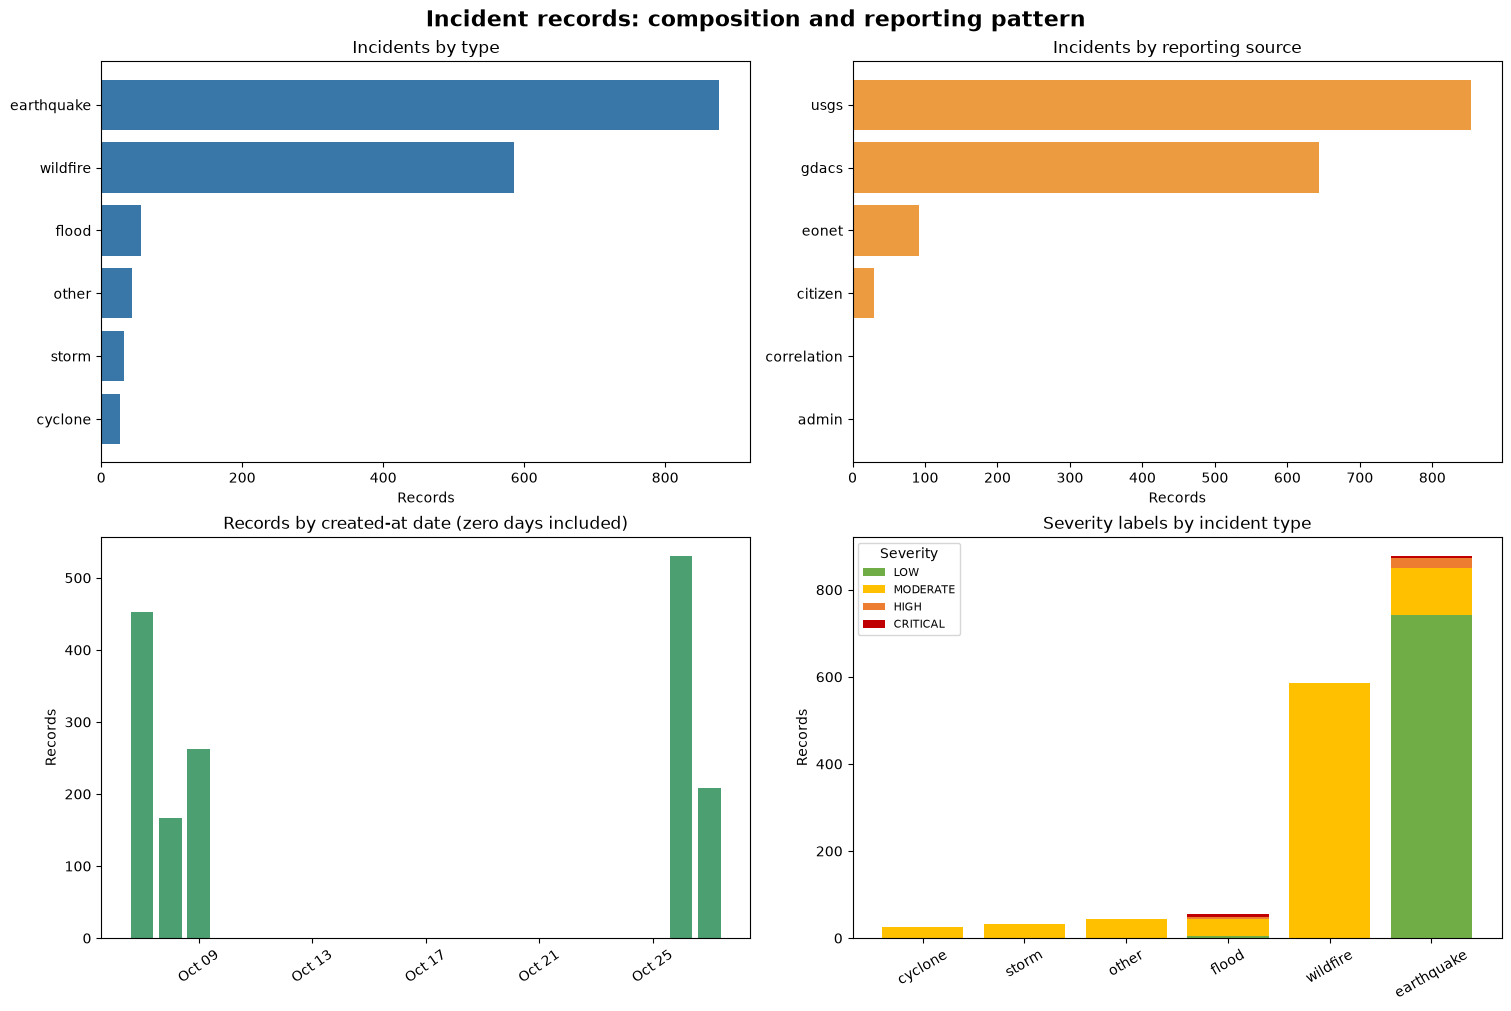

In [3]:
type_rows = query("SELECT type, COUNT(*) AS n FROM incidents GROUP BY type ORDER BY n")
source_rows = query("SELECT source, COUNT(*) AS n FROM incidents GROUP BY source ORDER BY n")
daily_rows = query(
    "SELECT DATE(created_at) AS day, COUNT(*) AS n FROM incidents "
    "WHERE created_at IS NOT NULL GROUP BY DATE(created_at) ORDER BY day"
)
severity_rows = query(
    "SELECT type, severity, COUNT(*) AS n FROM incidents GROUP BY type, severity"
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
fig.suptitle("Incident records: composition and reporting pattern", fontsize=16, fontweight="bold")

axes[0, 0].barh([row["type"] for row in type_rows], [row["n"] for row in type_rows], color="#3977a8")
axes[0, 0].set_title("Incidents by type")
axes[0, 0].set_xlabel("Records")

axes[0, 1].barh([row["source"] for row in source_rows], [row["n"] for row in source_rows], color="#ed9b40")
axes[0, 1].set_title("Incidents by reporting source")
axes[0, 1].set_xlabel("Records")

if daily_rows:
    daily_counts = {datetime.strptime(row["day"], "%Y-%m-%d").date(): row["n"] for row in daily_rows}
    start_day, end_day = min(daily_counts), max(daily_counts)
    date_span = [start_day + timedelta(days=offset) for offset in range((end_day - start_day).days + 1)]
    axes[1, 0].bar(date_span, [daily_counts.get(day, 0) for day in date_span], color="#4c9f70")
    axes[1, 0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
    axes[1, 0].tick_params(axis="x", rotation=35)
axes[1, 0].set_title("Records by created-at date (zero days included)")
axes[1, 0].set_ylabel("Records")

severity_order = ["LOW", "MODERATE", "HIGH", "CRITICAL"]
severity_colors = {"LOW": "#70ad47", "MODERATE": "#ffc000", "HIGH": "#ed7d31", "CRITICAL": "#c00000"}
severity_counts = defaultdict(dict)
for row in severity_rows:
    severity_counts[row["type"]][row["severity"]] = row["n"]
event_types = [row["type"] for row in type_rows]
bottom = [0] * len(event_types)
for level in severity_order:
    values = [severity_counts[event_type].get(level, 0) for event_type in event_types]
    axes[1, 1].bar(event_types, values, bottom=bottom, label=level, color=severity_colors[level])
    bottom = [base + value for base, value in zip(bottom, values)]
axes[1, 1].set_title("Severity labels by incident type")
axes[1, 1].set_ylabel("Records")
axes[1, 1].tick_params(axis="x", rotation=30)
axes[1, 1].legend(title="Severity", fontsize=8)

plt.show()

## Observation 2 — where records are located and what predictions contain

The coordinate plot is a longitude/latitude scatter, **not a basemap or density estimate**; overlapping feed records can hide one another. The prediction chart counts stored labels only. The dataset does not establish that predictions were correct, calibrated, or independently validated. The operations chart also makes empty or sparsely populated resource tables explicit.

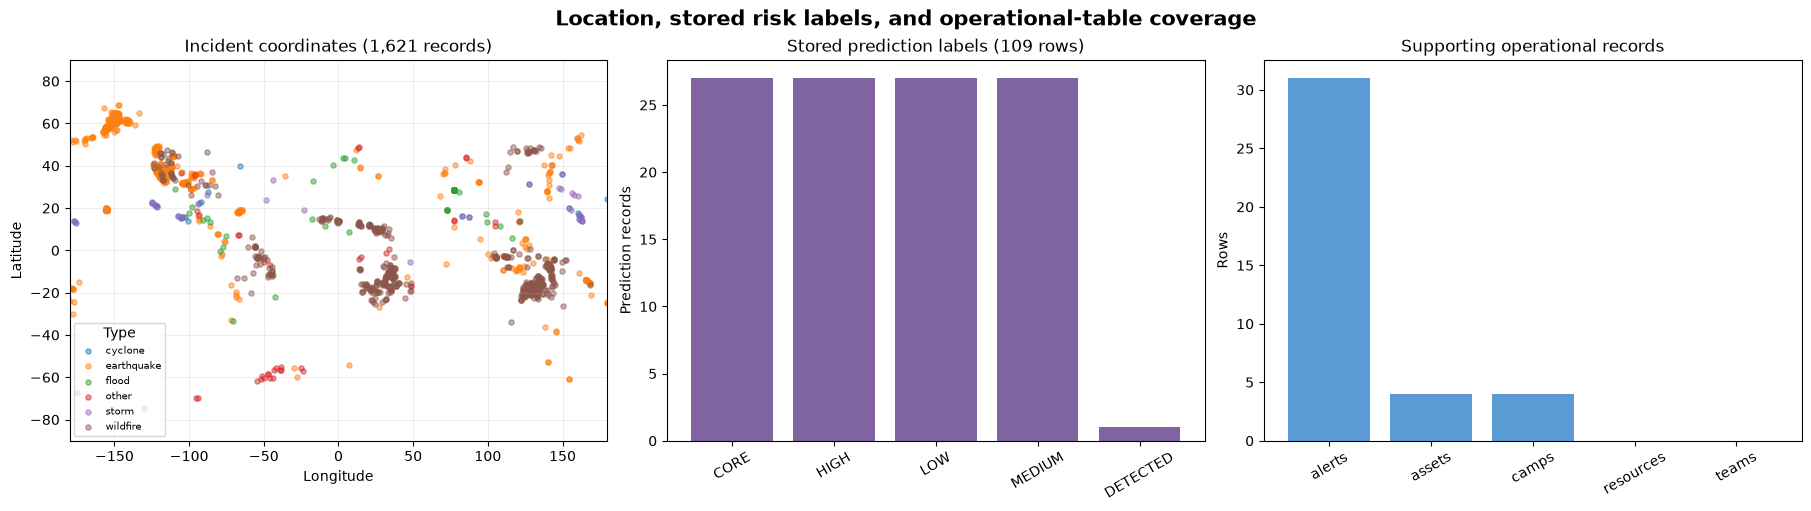

Prediction labels by hazard:
  cyclone / CORE: 2
  cyclone / HIGH: 2
  cyclone / LOW: 2
  cyclone / MEDIUM: 2
  earthquake / CORE: 7
  earthquake / HIGH: 7
  earthquake / LOW: 7
  earthquake / MEDIUM: 7
  flood / CORE: 11
  flood / HIGH: 11
  flood / LOW: 11
  flood / MEDIUM: 11
  flood_detected / DETECTED: 1
  other / CORE: 2
  other / HIGH: 2
  other / LOW: 2
  other / MEDIUM: 2
  wildfire / CORE: 5
  wildfire / HIGH: 5
  wildfire / LOW: 5
  wildfire / MEDIUM: 5
Treat these as stored model outputs, not measured outcomes or accuracy evidence.


In [4]:
geo_rows = query(
    "SELECT latitude, longitude, type FROM incidents "
    "WHERE latitude IS NOT NULL AND longitude IS NOT NULL"
)
prediction_rows = query(
    "SELECT risk_level, COUNT(*) AS n FROM predictions GROUP BY risk_level ORDER BY n DESC, risk_level"
)
prediction_total = table_counts.get("predictions", 0)
support_tables = ["alerts", "assets", "camps", "resources", "teams"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
fig.suptitle("Location, stored risk labels, and operational-table coverage", fontsize=15, fontweight="bold")

geo_by_type = defaultdict(lambda: {"longitude": [], "latitude": []})
for row in geo_rows:
    geo_by_type[row["type"]]["longitude"].append(row["longitude"])
    geo_by_type[row["type"]]["latitude"].append(row["latitude"])
for event_type, points in sorted(geo_by_type.items()):
    axes[0].scatter(points["longitude"], points["latitude"], s=14, alpha=0.48, label=event_type)
axes[0].set_xlim(-180, 180)
axes[0].set_ylim(-90, 90)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].set_title(f"Incident coordinates ({len(geo_rows):,} records)")
axes[0].grid(alpha=0.2)
axes[0].legend(title="Type", fontsize=7, loc="lower left")

if prediction_rows:
    risk_labels = [row["risk_level"] for row in prediction_rows]
    risk_counts = [row["n"] for row in prediction_rows]
    axes[1].bar(risk_labels, risk_counts, color="#8064a2")
    axes[1].tick_params(axis="x", rotation=30)
axes[1].set_title(f"Stored prediction labels ({prediction_total:,} rows)")
axes[1].set_ylabel("Prediction records")

axes[2].bar(support_tables, [table_counts.get(name, 0) for name in support_tables], color="#5b9bd5")
axes[2].set_title("Supporting operational records")
axes[2].set_ylabel("Rows")
axes[2].tick_params(axis="x", rotation=30)

plt.show()

if prediction_total:
    prediction_hazards = query(
        "SELECT hazard_type, risk_level, COUNT(*) AS n FROM predictions "
        "GROUP BY hazard_type, risk_level ORDER BY hazard_type, risk_level"
    )
    print("Prediction labels by hazard:")
    for row in prediction_hazards:
        print(f"  {row['hazard_type']} / {row['risk_level']}: {row['n']}")
    print("Treat these as stored model outputs, not measured outcomes or accuracy evidence.")

## Takeaways and limitations

- Event type and source are strongly imbalanced; compare within source and event type before drawing conclusions from raw counts.
- A short, bursty `created_at` timeline can indicate feed ingestion or seeded data, not a sustained trend in hazards.
- Most incident rows may carry an active status because the table records feed detections; status should not be read as unresolved real-world emergencies without lifecycle context.
- Very small or empty operational tables limit conclusions about response resources. Prediction labels are not ground-truth outcomes.
- For stronger analysis, retain source identifiers and ingestion timestamps, deduplicate cross-feed events, validate coordinates and severity conventions, and compare predictions with later observed outcomes.

Re-run the setup and analysis cells after the database changes. Close the read-only connection when finished.

In [ ]:
connection.close()

In [5]:
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc
)
from sklearn.calibration import calibration_curve
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [6]:
# In Google Colab, upload train.csv when prompted.
# In Jupyter locally, place train.csv beside this notebook or choose it with the file picker.

data_path = "train.csv"

if not os.path.exists(data_path):
    try:
        from google.colab import files
        uploaded = files.upload()
        csv_files = [name for name in uploaded if name.lower().endswith(".csv")]
        if not csv_files:
            raise FileNotFoundError("Please upload the Kaggle train.csv file.")
        data_path = csv_files[0]
    except ImportError:
        try:
            import tkinter as tk
            from tkinter import filedialog
            root = tk.Tk()
            root.withdraw()
            data_path = filedialog.askopenfilename(
                title="Select Kaggle train.csv",
                filetypes=[("CSV files", "*.csv")]
            )
            root.destroy()
            if not data_path:
                raise FileNotFoundError(
                    "Place train.csv in the notebook folder and run this cell again."
                )
        except Exception as exc:
            raise FileNotFoundError(
                "Could not find train.csv. Download it from the Kaggle dataset page "
                "linked in the notebook introduction, then place it beside this notebook."
            ) from exc

df = pd.read_csv(data_path)
required = {"text", "target"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing)}")

df = df[["text", "target"]].dropna(subset=["text", "target"]).copy()
df["text"] = df["text"].astype(str).str.strip()
df = df[df["text"] != ""]
df["target"] = df["target"].astype(int)
df = df[df["target"].isin([0, 1])]

print(f"Rows: {len(df):,}")
print(f"Columns used: {list(df.columns)}")
display(df.head())
print("\nClass counts:")
display(df["target"].value_counts().rename(index={0: "Not disaster", 1: "Disaster"}).to_frame("count"))

Rows: 7,613
Columns used: ['text', 'target']


,text,target
0,Our Deeds are the Reason of this #earthquake M...,1
1,Forest fire near La Ronge Sask. Canada,1
2,All residents asked to 'shelter in place' are ...,1
3,"13,000 people receive #wildfires evacuation or...",1
4,Just got sent this photo from Ruby #Alaska as ...,1



Class counts:


,count
target,
Not disaster,4342
Disaster,3271


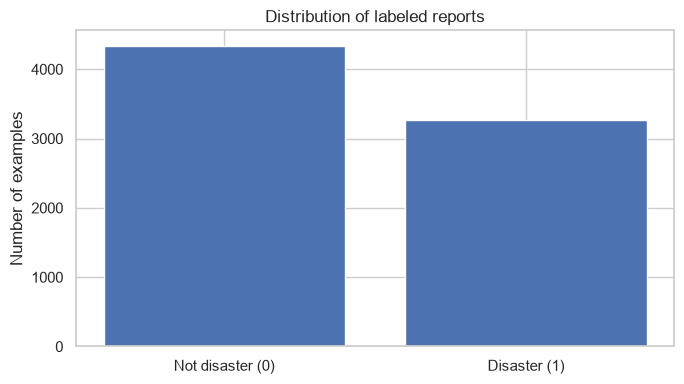

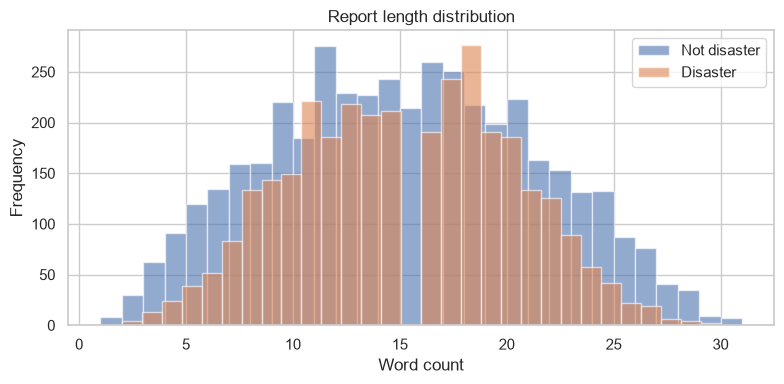

,count,mean,std,min,25%,50%,75%,max
target,,,,,,,,
Not disaster,4342.0,14.704744,6.161564,1.0,10.0,15.0,19.0,31.0
Disaster,3271.0,15.167533,5.096806,2.0,11.0,15.0,19.0,30.0


In [7]:
# Class balance
class_counts = df["target"].value_counts().sort_index()
plt.figure(figsize=(7, 4))
plt.bar(["Not disaster (0)", "Disaster (1)"], [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Distribution of labeled reports")
plt.ylabel("Number of examples")
plt.tight_layout()
plt.show()

# Text length distribution
df["text_length_words"] = df["text"].astype(str).str.split().str.len()
plt.figure(figsize=(8, 4))
for label, name in [(0, "Not disaster"), (1, "Disaster")]:
    values = df.loc[df["target"] == label, "text_length_words"]
    plt.hist(values, bins=30, alpha=0.6, label=name)
plt.title("Report length distribution")
plt.xlabel("Word count")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

display(df.groupby("target")["text_length_words"].describe().rename(index={0: "Not disaster", 1: "Disaster"}))

In [8]:
X = df["text"].astype(str)
y = df["target"].astype(int)

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=True,
        strip_accents="unicode",
        ngram_range=(1, 2),
        min_df=2,
        max_features=50000,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_valid)
y_prob = model.predict_proba(X_valid)[:, 1]

print(f"Training examples: {len(X_train):,}")
print(f"Validation examples: {len(X_valid):,}")
print("Training complete.")

Training examples: 6,090
Validation examples: 1,523
Training complete.


,Metric,Score
0,Accuracy,0.795
1,Precision,0.757
2,Recall,0.771
3,F1 score,0.764


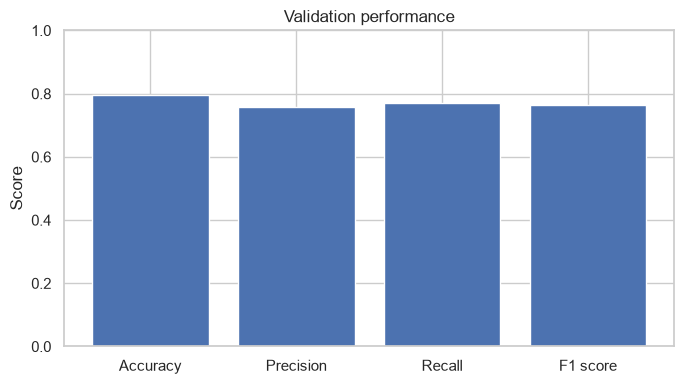

              precision    recall  f1-score   support

Not disaster       0.82      0.81      0.82       869
    Disaster       0.76      0.77      0.76       654

    accuracy                           0.80      1523
   macro avg       0.79      0.79      0.79      1523
weighted avg       0.80      0.80      0.80      1523



In [9]:
metrics = {
    "Accuracy": accuracy_score(y_valid, y_pred),
    "Precision": precision_score(y_valid, y_pred, zero_division=0),
    "Recall": recall_score(y_valid, y_pred, zero_division=0),
    "F1 score": f1_score(y_valid, y_pred, zero_division=0)
}
metrics_df = pd.DataFrame({"Metric": list(metrics.keys()), "Score": list(metrics.values())})
display(metrics_df.style.format({"Score": "{:.3f}"}))

plt.figure(figsize=(7, 4))
plt.bar(metrics_df["Metric"], metrics_df["Score"])
plt.ylim(0, 1)
plt.title("Validation performance")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

print(classification_report(
    y_valid, y_pred, labels=[0, 1],
    target_names=["Not disaster", "Disaster"], zero_division=0
))

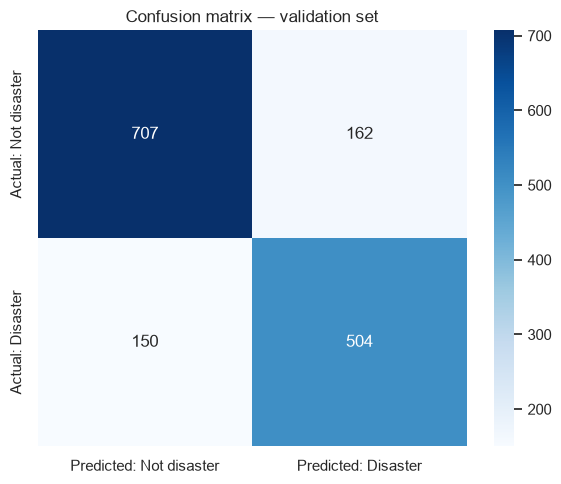

In [10]:
cm = confusion_matrix(y_valid, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted: Not disaster", "Predicted: Disaster"],
    yticklabels=["Actual: Not disaster", "Actual: Disaster"]
)
plt.title("Confusion matrix — validation set")
plt.tight_layout()
plt.show()

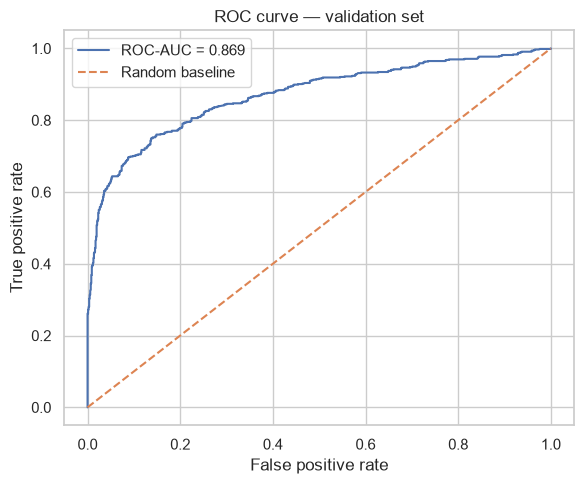

ROC-AUC: 0.869


In [11]:
fpr, tpr, thresholds = roc_curve(y_valid, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve — validation set")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")

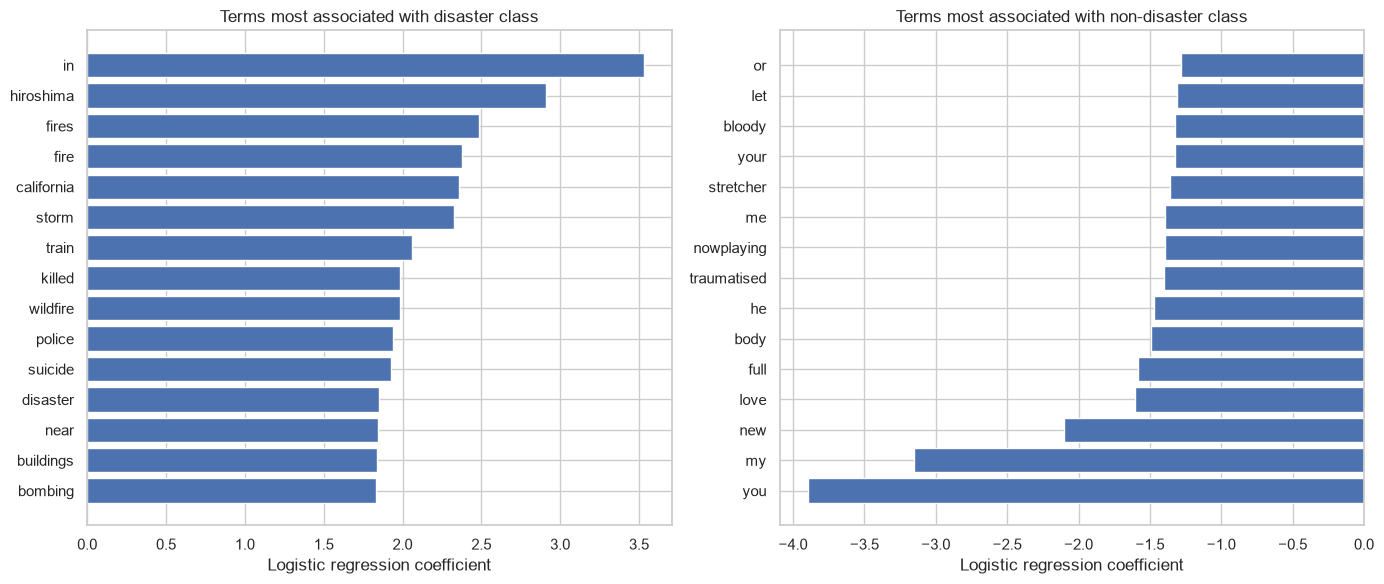

In [12]:
vectorizer = model.named_steps["tfidf"]
classifier = model.named_steps["classifier"]
feature_names = np.array(vectorizer.get_feature_names_out())
coefs = classifier.coef_[0]

top_disaster_idx = np.argsort(coefs)[-15:]
top_non_disaster_idx = np.argsort(coefs)[:15]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].barh(feature_names[top_disaster_idx], coefs[top_disaster_idx])
axes[0].set_title("Terms most associated with disaster class")
axes[0].set_xlabel("Logistic regression coefficient")
axes[1].barh(feature_names[top_non_disaster_idx], coefs[top_non_disaster_idx])
axes[1].set_title("Terms most associated with non-disaster class")
axes[1].set_xlabel("Logistic regression coefficient")
plt.tight_layout()
plt.show()

In [13]:
examples = [
    "Flood water is rising near the village and families need evacuation.",
    "I am devastated that my favorite show ended today.",
    "Earthquake damaged several buildings and emergency crews are responding.",
    "This traffic jam is a disaster; I will be late for work."
]

example_prob = model.predict_proba(examples)[:, 1]
example_pred = model.predict(examples)

example_results = pd.DataFrame({
    "Report": examples,
    "Predicted label": ["Disaster-related" if p == 1 else "Not disaster-related" for p in example_pred],
    "Estimated disaster probability": example_prob
})
display(example_results.style.format({"Estimated disaster probability": "{:.1%}"}))

,Report,Predicted label,Estimated disaster probability
0,Flood water is rising near the village and families need evacuation.,Disaster-related,79.1%
1,I am devastated that my favorite show ended today.,Not disaster-related,17.1%
2,Earthquake damaged several buildings and emergency crews are responding.,Disaster-related,80.0%
3,This traffic jam is a disaster; I will be late for work.,Not disaster-related,47.8%


In [14]:
model_path = "disasterwatch_text_classifier.joblib"
metrics_path = "disasterwatch_validation_metrics.csv"

joblib.dump(model, model_path)
metrics_df.to_csv(metrics_path, index=False)

print(f"Saved model: {model_path}")
print(f"Saved metrics: {metrics_path}")

Saved model: disasterwatch_text_classifier.joblib
Saved metrics: disasterwatch_validation_metrics.csv
